In [9]:
using Pkg

Pkg.activate(".")

using OptimalTransport
using Distances
using Tulip

using LinearAlgebra
using Random
using Distributions
using StatsBase
using Plots

  Activating project at `~/Documents/GitHub/Julia_Tutorials/OptimalTransport`
[ Info: Precompiling IJuliaExt [2f4121a4-3b3a-5ce6-9c5e-1f2673ce168a]


In [125]:
Random.seed!(3)
σ1 = MvNormal(I(2))
N = 100
μ = fill(1 / N, N)
μsupport = rand(σ1,100)'

M = 50
σ2 = MvNormal([5,5],I(2))
ν = fill(1 / M, M)
νsupport = rand(σ2,M)';

C = pairwise(sqeuclidean, μsupport', νsupport'; dims=2);

# This is the exact total cost
γ = emd2(μ, ν, C, Tulip.Optimizer());

ε = .5

# This is the exact sinkhorn cost
s = sinkhorn2(μ, ν, C, ε);

In [129]:
5^2 + 5^2

50

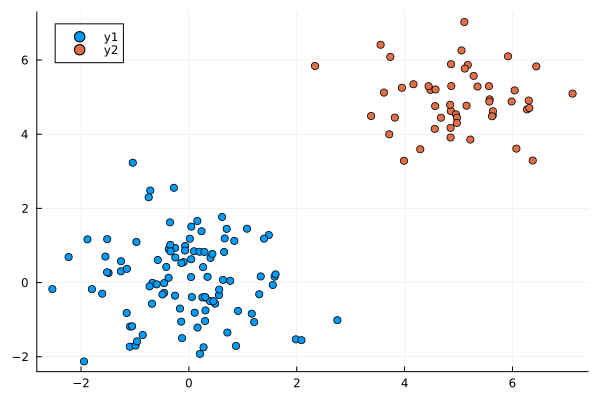

In [118]:
scatter(μsupport[:,1],μsupport[:,2])
scatter!(νsupport[:,1],νsupport[:,2])